# Chiến lược EMA 9/21 realtime cho BTCUSDT

Demo Phần 4 · SQL với Python. Notebook này chạy đúng flow của hệ thống:

**`crypto_trades` (QuestDB) → SQL gộp nến 1 phút → EMA 9/21 → tín hiệu BUY/SELL → bảng `signals`**

- Chỉ dùng dữ liệu **trong ngày hôm nay** (UTC) và chỉ **nến đã đóng**.
- **Long only** trên BTCUSDT spot: BUY khi đang không giữ BTC và EMA 9 cắt lên EMA 21; SELL khi đang giữ và EMA 9 cắt xuống.
- Bảng `signals` **chỉ ghi khi tín hiệu xuất hiện**, không ghi mỗi phút.

**Cần chạy trước:** QuestDB ở `localhost:9000`, và `python -m streams.binance` đang ghi trade vào `crypto_trades`.
Mở notebook trong thư mục dự án (nơi có `qdb.py` và `.env`).

## 1. Cấu hình

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import clear_output, display

# Tìm qdb.py (helper dùng chung của dự án) từ thư mục hiện tại trở lên
root = Path.cwd()
while not (root / "qdb.py").exists():
    if root == root.parent:
        raise FileNotFoundError("Không tìm thấy qdb.py: hãy mở notebook trong thư mục dự án")
    root = root.parent
sys.path.insert(0, str(root))
from qdb import sql, write

SYMBOL, EXCHANGE, MARKET = "BTCUSDT", "binance", "spot"
FAST, SLOW = 9, 21
STRATEGY = f"ewma_{FAST}_{SLOW}"
TZ = "Asia/Ho_Chi_Minh"   # chỉ dùng để hiển thị; database lưu theo UTC
LOOP_MINUTES = 30         # số phút chạy vòng lặp realtime ở bước 6

## 2. Tạo bảng `signals`

Mỗi dòng là **một tín hiệu**, ghi lúc nó xuất hiện. Ít dòng mỗi ngày nên `PARTITION BY YEAR`.
Có `DEDUP` nên chạy lại notebook nhiều lần cũng không bị trùng tín hiệu.

In [2]:
sql("""
CREATE TABLE IF NOT EXISTS signals (
  timestamp TIMESTAMP,   -- lúc tín hiệu xuất hiện (nến 1 phút vừa đóng)
  strategy  SYMBOL,      -- ewma_9_21
  exchange  SYMBOL,
  symbol    SYMBOL,
  side      SYMBOL,      -- BUY / SELL
  price     DOUBLE,      -- giá đóng cửa của nến tạo tín hiệu
  ema_fast  DOUBLE,
  ema_slow  DOUBLE
) TIMESTAMP(timestamp) PARTITION BY YEAR WAL
  DEDUP UPSERT KEYS(timestamp, strategy, symbol);
""")

""


## 3. Kiểm tra dữ liệu trade hôm nay

In [3]:
sql(f"""
SELECT count() AS trades, min(timestamp) AS first_trade, max(timestamp) AS last_trade
FROM crypto_trades
WHERE symbol = '{SYMBOL}' AND exchange = '{EXCHANGE}' AND market = '{MARKET}'
  AND timestamp IN today()
""")

,trades,first_trade,last_trade
0,87306,2026-11-06 03:16:12.575649,2026-11-06 03:49:18.776891


## 4. Query bằng Python: gộp trade thành nến 1 phút

`SAMPLE BY 1m` gộp ngay trong database, Python chỉ nhận về vài trăm dòng thay vì hàng chục nghìn trade.
Bỏ phút đang chạy để không tính trên nến chưa đóng.

In [4]:
BARS_SQL = f"""
SELECT timestamp,
       first(price) AS open, max(price) AS high, min(price) AS low, last(price) AS close,
       sum(qty) AS volume, count() AS trades
FROM crypto_trades
WHERE symbol = '{SYMBOL}' AND exchange = '{EXCHANGE}' AND market = '{MARKET}'
  AND timestamp IN today()                      -- chỉ dữ liệu hôm nay (UTC)
  AND timestamp < timestamp_floor('m', now())   -- chỉ nến đã đóng
SAMPLE BY 1m
"""
# Nếu QuestDB báo lỗi với today(), thay dòng đó bằng:
#   AND timestamp >= timestamp_floor('d', now())


def load_bars():
    bars = sql(BARS_SQL)
    bars["timestamp"] = pd.to_datetime(bars["timestamp"], utc=True)
    return bars.sort_values("timestamp").reset_index(drop=True)


bars = load_bars()
print(f"{len(bars)} nến 1 phút, từ {bars.timestamp.min()} đến {bars.timestamp.max()} (UTC)")
bars.tail()

33 nến 1 phút, từ 2026-11-06 03:16:00+00:00 đến 2026-11-06 03:48:00+00:00 (UTC)


,timestamp,open,high,low,close,volume,trades
28,2026-11-06 03:44:00+00:00,75892.06,75934.01,75892.05,75904.04,6.01596,2142
29,2026-11-06 03:45:00+00:00,75904.04,75972.01,75894.45,75967.00,4.44323,2300
30,2026-11-06 03:46:00+00:00,75967.00,75983.88,75952.01,75954.01,4.02226,1839
31,2026-11-06 03:47:00+00:00,75954.00,75974.01,75954.00,75970.00,5.17786,1819
32,2026-11-06 03:48:00+00:00,75970.01,75970.01,75907.89,75932.01,3.91598,3702


## 5. Chiến lược: EMA 9/21, long only

$$EMA_t = \alpha \cdot P_t + (1-\alpha)\cdot EMA_{t-1}, \qquad \alpha = \frac{2}{N+1}$$

- **Vào:** bảng nến (`timestamp`, `close`).
- **Ra:** các dòng tín hiệu, chỉ tại thời điểm EMA 9 cắt EMA 21.
- **BUY** khi đang không giữ BTC và EMA 9 cắt lên; **SELL** khi đang giữ và EMA 9 cắt xuống.
- Bỏ qua 21 nến đầu ngày để EMA ổn định.

0 tín hiệu hôm nay


,timestamp,side,price,ema_fast,ema_slow


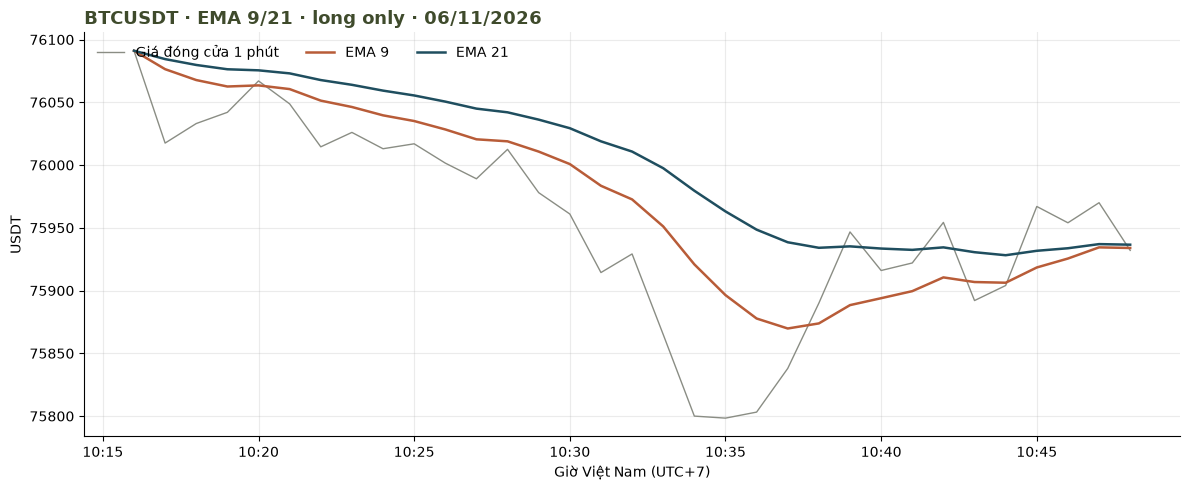

In [5]:
def ewma_strategy(bars, fast=FAST, slow=SLOW):
    df = bars[["timestamp", "close"]].copy()
    df["ema_fast"] = df["close"].ewm(span=fast, adjust=False).mean()
    df["ema_slow"] = df["close"].ewm(span=slow, adjust=False).mean()
    df["above"] = df["ema_fast"] > df["ema_slow"]
    df["cross"] = df["above"].astype(int).diff().fillna(0)   # +1 cắt lên, -1 cắt xuống
    df.loc[df.index < slow, "cross"] = 0                      # giai đoạn khởi động EMA

    rows, holding = [], False                                 # long only: bắt đầu không giữ BTC
    for r in df.itertuples():
        if r.cross == 1 and not holding:
            side, holding = "BUY", True
        elif r.cross == -1 and holding:
            side, holding = "SELL", False
        else:
            continue
        rows.append({"timestamp": r.timestamp + pd.Timedelta(minutes=1),   # tín hiệu có khi nến đóng
                     "side": side, "price": r.close,
                     "ema_fast": r.ema_fast, "ema_slow": r.ema_slow})
    signals = pd.DataFrame(rows, columns=["timestamp", "side", "price", "ema_fast", "ema_slow"])
    signals["timestamp"] = pd.to_datetime(signals["timestamp"], utc=True)   # giữ kiểu thời gian kể cả khi chưa có tín hiệu
    return df, signals


def to_db(signals):
    """Ghi tín hiệu vào bảng signals (cột chữ -> SYMBOL)."""
    out = signals.assign(strategy=STRATEGY, exchange=EXCHANGE, symbol=SYMBOL)[
        ["timestamp", "strategy", "exchange", "symbol", "side", "price", "ema_fast", "ema_slow"]]
    for c in ("strategy", "exchange", "symbol", "side"):
        out[c] = out[c].astype("category")
    write("signals", out, at="timestamp")


def plot(df, signals, path=None, title_extra=""):
    t = df["timestamp"].dt.tz_convert(TZ)
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(t, df["close"], color="#8A8D84", lw=1, label="Giá đóng cửa 1 phút")
    ax.plot(t, df["ema_fast"], color="#B85C38", lw=1.8, label=f"EMA {FAST}")
    ax.plot(t, df["ema_slow"], color="#1F4E5F", lw=1.8, label=f"EMA {SLOW}")
    for side, marker, color in (("BUY", "^", "#4A6B2A"), ("SELL", "v", "#B85C38")):
        s = signals[signals["side"] == side]
        if s.empty:
            continue
        ax.scatter(s["timestamp"].dt.tz_convert(TZ), s["price"], marker=marker, s=110,
                   color=color, edgecolor="white", linewidth=0.8, zorder=3, label=side)
    ax.set_title(f"{SYMBOL} · EMA {FAST}/{SLOW} · long only · {pd.Timestamp.now(tz=TZ):%d/%m/%Y}{title_extra}",
                 loc="left", fontsize=13, color="#3F4B2C", fontweight="bold")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=TZ))
    ax.set_xlabel("Giờ Việt Nam (UTC+7)")
    ax.set_ylabel("USDT")
    ax.grid(alpha=0.25)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), frameon=False, ncol=5)
    fig.tight_layout()
    if path:
        fig.savefig(path, dpi=200, facecolor="white")
    plt.show()


df, signals = ewma_strategy(bars)
print(f"{len(signals)} tín hiệu hôm nay")
display(signals)
plot(df, signals, path="fig_signals_today.png")
if len(signals):
    to_db(signals)   # DEDUP: ghi lại nhiều lần vẫn không trùng

## 6. Vòng lặp realtime

Mỗi phút: chờ nến đóng → query → tính EMA → nếu có tín hiệu **mới** thì ghi vào `signals`.
Mặc định chạy `LOOP_MINUTES` phút; bấm **Interrupt** (■) để dừng sớm.

11:05:05 | close 75,720.00 | EMA9 75,822.55 | EMA21 75,863.02 | EMA9 < EMA21 | vị thế FLAT
11:06:05 | close 75,754.00 | EMA9 75,808.84 | EMA21 75,853.11 | EMA9 < EMA21 | vị thế FLAT
11:07:05 | close 75,796.01 | EMA9 75,806.27 | EMA21 75,847.92 | EMA9 < EMA21 | vị thế FLAT
11:08:05 | close 75,736.32 | EMA9 75,792.28 | EMA21 75,837.78 | EMA9 < EMA21 | vị thế FLAT
11:09:05 | close 75,712.14 | EMA9 75,776.26 | EMA21 75,826.35 | EMA9 < EMA21 | vị thế FLAT
11:10:05 | close 75,700.00 | EMA9 75,761.00 | EMA21 75,814.87 | EMA9 < EMA21 | vị thế FLAT
11:11:05 | close 75,692.34 | EMA9 75,747.27 | EMA21 75,803.73 | EMA9 < EMA21 | vị thế FLAT
11:12:05 | close 75,734.00 | EMA9 75,744.62 | EMA21 75,797.39 | EMA9 < EMA21 | vị thế FLAT
11:13:05 | close 75,777.58 | EMA9 75,751.21 | EMA21 75,795.59 | EMA9 < EMA21 | vị thế FLAT
11:14:05 | close 75,772.01 | EMA9 75,755.37 | EMA21 75,793.45 | EMA9 < EMA21 | vị thế FLAT
11:15:05 | close 75,744.01 | EMA9 75,753.10 | EMA21 75,788.95 | EMA9 < EMA21 | vị thế FLAT

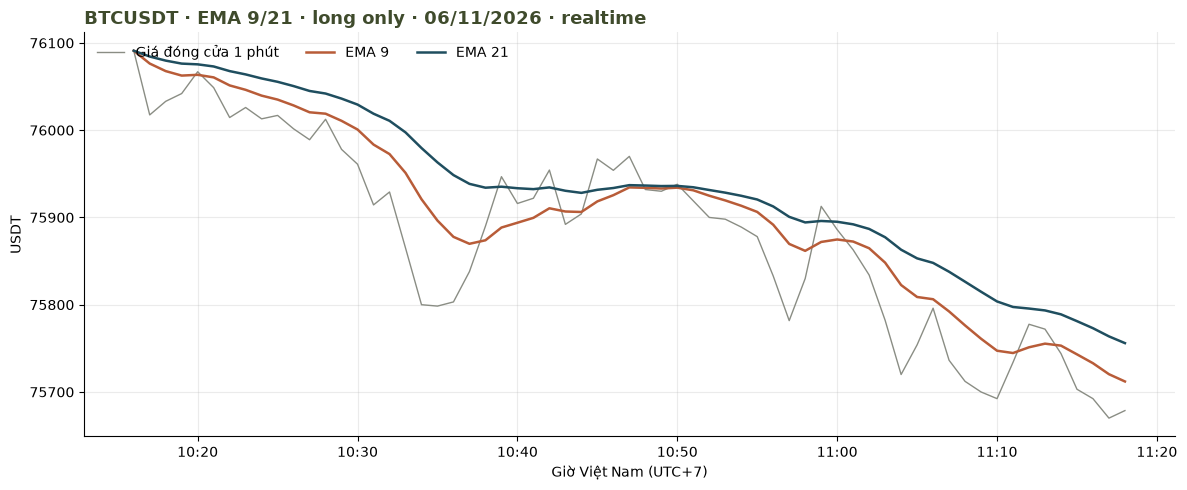

In [6]:
def wait_next_minute(delay=5):
    """Ngủ tới đầu phút kế tiếp, cộng vài giây để nến kịp đóng và dữ liệu kịp ghi."""
    time.sleep(60 - time.time() % 60 + delay)


old = sql(f"""
SELECT timestamp FROM signals
WHERE strategy = '{STRATEGY}' AND symbol = '{SYMBOL}' AND timestamp IN today()
""")
seen = set(pd.to_datetime(old["timestamp"], utc=True))
log = []

try:
    for _ in range(LOOP_MINUTES):
        wait_next_minute()
        bars = load_bars()
        if len(bars) <= SLOW:
            print(f"Mới có {len(bars)} nến, cần hơn {SLOW} nến để tính EMA {SLOW}")
            continue
        df, signals = ewma_strategy(bars)
        new = signals[~signals["timestamp"].isin(seen)]
        if len(new):
            to_db(new)
            seen.update(new["timestamp"])

        last = df.iloc[-1]
        position = "LONG" if len(signals) and signals["side"].iloc[-1] == "BUY" else "FLAT"
        line = (f"{pd.Timestamp.now(tz=TZ):%H:%M:%S} | close {last.close:,.2f} | "
                f"EMA{FAST} {last.ema_fast:,.2f} | EMA{SLOW} {last.ema_slow:,.2f} | "
                f"{'EMA9 > EMA21' if last.above else 'EMA9 < EMA21'} | vị thế {position}")
        if len(new):
            line += "  >>> " + ", ".join(f"{r.side} @ {r.price:,.2f}" for r in new.itertuples())
        log.append(line)

        clear_output(wait=True)
        print("\n".join(log[-15:]))
        recent = df.tail(180)   # 3 giờ gần nhất cho dễ nhìn
        plot(recent, signals[signals["timestamp"] >= recent["timestamp"].min()], title_extra=" · realtime")
except KeyboardInterrupt:
    print("Đã dừng vòng lặp.")

## 7. Kết quả: tín hiệu đã lưu trong database

,timestamp,strategy,exchange,symbol,side,price,ema_fast,ema_slow


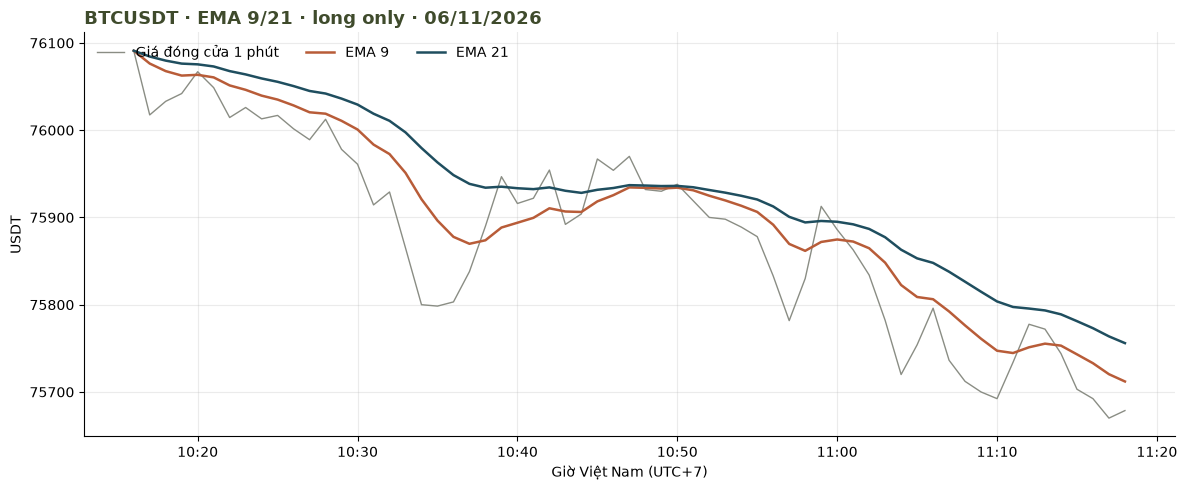

In [7]:
saved = sql(f"""
SELECT * FROM signals
WHERE strategy = '{STRATEGY}' AND symbol = '{SYMBOL}' AND timestamp IN today()
ORDER BY timestamp DESC
""")
display(saved)

bars = load_bars()
df, signals = ewma_strategy(bars)
plot(df, signals, path="fig_signals_final.png")

## 8. Ảnh cần gửi lại để làm slide

1. **Slide 7:** output của bước 4 (`bars.tail()`).
2. **Slide 9:** output của vòng lặp ở bước 6, sau khi chạy ít nhất 10–15 phút, càng tốt nếu có một dòng `>>> BUY` hoặc `>>> SELL`.
3. **Slide 10:** file `fig_signals_final.png` (lưu cạnh notebook).
4. **Slide 10:** ảnh chụp web console `localhost:9000` khi chạy câu SQL dưới đây.

```sql
SELECT * FROM signals
WHERE timestamp IN today()
ORDER BY timestamp DESC;
```